# Data Understanding and Cleaning (CDS4003)
Run from the repository root. The raw Kaggle dataset is downloaded only if `vehicles.csv` is absent.


In [ ]:
# Download the raw Kaggle dataset if vehicles.csv is not already available.
# Kaggle credentials must be configured on your machine; do not upload kaggle.json to GitHub.
from pathlib import Path
import subprocess
import zipfile

ROOT = Path.cwd()
if not (ROOT / "vehicles.csv").exists():
    print("vehicles.csv not found; attempting download from Kaggle...")
    try:
        subprocess.run(["kaggle", "datasets", "download",
                        "-d", "austinreese/craigslist-carstrucks-data", "-p", str(ROOT)],
                       check=True)
    except (subprocess.CalledProcessError, FileNotFoundError) as exc:
        raise RuntimeError(
            "Download vehicles.csv from https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data "
            "and put it in the repository root, or configure your Kaggle API credentials and install kaggle."
        ) from exc
    archive = ROOT / "craigslist-carstrucks-data.zip"
    if archive.exists():
        with zipfile.ZipFile(archive) as zf:
            zf.extract("vehicles.csv", path=ROOT)

assert (ROOT / "vehicles.csv").exists(), "Missing vehicles.csv in repository root"
(ROOT / "outputs" / "figures").mkdir(parents=True, exist_ok=True)
print("Dataset location:", ROOT / "vehicles.csv")


In [2]:
# ==========================================
# CELL 2: Initial Inspection (Stage 2.2 & 3.1)
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Relative path use karein (no personal file paths)
df = pd.read_csv("vehicles.csv")

print("=== STAGE 2.2: DATASET SIZE & STRUCTURE ===")
print(f"Total Rows: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"Numerical Columns ({len(num_cols)}): {num_cols}")
print(f"Categorical/Text Columns ({len(cat_cols)}): {cat_cols}")

print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Data Info ---")
df.info()

print("\n--- Descriptive Statistics (Numerical) ---")
display(df.describe().T)

/tmp/ipykernel_1841/2663190118.py:10: DtypeWarning: Columns (4,32,40) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("vehicles.csv")


=== STAGE 2.2: DATASET SIZE & STRUCTURE ===
Total Rows: 295,451
Total Columns: 41
Numerical Columns (11): ['id', 'year', 'odometer', 'size', 'county', 'lat', 'long', 'image_count', 'delivery_available', 'odometer_broken', 'odometer_rolled_over']
Categorical/Text Columns (30): ['url', 'region', 'region_url', 'price', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'title_status', 'transmission', 'VIN', 'drive', 'type', 'paint_color', 'image_url', 'description', 'state', 'posting_date', 'seller_type', 'title', 'updated_date', 'address_street', 'address_city', 'address_state', 'address_postal_code', 'address_country', 'image_urls', 'monthly_payment', 'other_attributes']

--- First 5 Rows ---


,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,address_state,address_postal_code,address_country,image_count,image_urls,delivery_available,odometer_broken,odometer_rolled_over,monthly_payment,other_attributes
0,7994372850,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,27999,2022.0,ford,explorer st,excellent,6 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00N0N_aBzbdTBI4c...,0,0,0,NaN,NaN
1,7994372787,https://sfbay.craigslist.org/cto/d/mill-valley...,SF bay area,https://sfbay.craigslist.org,2200,1969.0,volkswagen,bug,fair,4 cylinders,...,CA,94942,US,4,https://images.craigslist.org/00n0n_gNzbApFpKG...,0,0,0,NaN,NaN
2,7994372559,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,15999,2016.0,rover,sport,excellent,6 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00Z0Z_3KNlCaCAM2...,0,0,0,NaN,NaN
3,7994372553,https://sfbay.craigslist.org/cto/d/napa-1974-c...,SF bay area,https://sfbay.craigslist.org,12000,1974.0,cadillac,eldorado convertible,good,8 cylinders,...,CA,94581,US,8,https://images.craigslist.org/00s0s_4aCpejyeUW...,0,0,0,NaN,NaN
4,7994372166,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,18999,2009.0,dodge,challenger lc srt8,excellent,8 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00T0T_4wec2Grzn3...,0,0,0,NaN,NaN



--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295451 entries, 0 to 295450
Data columns (total 41 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    295451 non-null  int64  
 1   url                   295451 non-null  object 
 2   region                295451 non-null  object 
 3   region_url            295451 non-null  object 
 4   price                 295451 non-null  object 
 5   year                  295425 non-null  float64
 6   manufacturer          284659 non-null  object 
 7   model                 292092 non-null  object 
 8   condition             159961 non-null  object 
 9   cylinders             215284 non-null  object 
 10  fuel                  294320 non-null  object 
 11  odometer              291415 non-null  float64
 12  title_status          288635 non-null  object 
 13  transmission          293895 non-null  object 
 14  VIN                   174332 non-

,count,mean,std,min,25%,50%,75%,max
id,295451.0,7.985641e+09,5.481825e+06,7.975321e+09,7.980935e+09,7.985959e+09,7.990508e+09,7.994391e+09
year,295425.0,2.012771e+03,1.158043e+01,1.900000e+03,2.010000e+03,2.015000e+03,2.019000e+03,2.027000e+03
odometer,291415.0,1.145619e+05,1.713099e+05,1.000000e+00,6.762650e+04,1.075000e+05,1.473720e+05,1.000000e+07
size,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
county,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lat,295302.0,3.876365e+01,6.235714e+00,-4.615658e+01,3.406140e+01,3.885162e+01,4.359500e+01,6.499370e+01
long,295302.0,-1.041550e+02,1.969101e+01,-1.597199e+02,-1.214659e+02,-1.109588e+02,-8.445520e+01,1.788775e+02
image_count,295451.0,1.709423e+01,6.917641e+00,0.000000e+00,1.200000e+01,1.900000e+01,2.400000e+01,2.400000e+01
delivery_available,295451.0,7.328796e-02,2.606090e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
odometer_broken,295451.0,6.918237e-03,8.288786e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00


In [3]:
# ==========================================
# CELL 3: Limitations & Bias Metrics (Stage 2.7)
# ==========================================
print("=== STAGE 2.7: TIME FRAME & REGIONAL DISTRIBUTION ===")
dates = pd.to_datetime(df['posting_date'], errors='coerce', utc=True)
print(f"Earliest posting_date: {dates.min()}")
print(f"Latest posting_date:   {dates.max()}")

print("\nTop 10 States by Listing Count:")
state_counts = df['state'].value_counts(dropna=False).head(10)
state_pct = (state_counts / len(df) * 100).round(2)
display(pd.DataFrame({'Count': state_counts, 'Percentage (%)': state_pct}))

=== STAGE 2.7: TIME FRAME & REGIONAL DISTRIBUTION ===
Earliest posting_date: 2026-09-30 07:17:53+00:00
Latest posting_date:   2026-11-03 04:41:25+00:00

Top 10 States by Listing Count:


,Count,Percentage (%)
state,,
ca,60110,20.35
or,30340,10.27
wa,24974,8.45
tx,16665,5.64
fl,15041,5.09
az,13183,4.46
co,11977,4.05
ny,11021,3.73
mn,7546,2.55


In [5]:
# ==========================================
# CELL 4 (FIXED): Data Quality Audit (Stage 3.2 & Table 3.3)
# ==========================================
print("=== SAMPLE RAW PRICE VALUES (Data Type Issue Evidence) ===")
print(df['price'].dropna().unique()[:15])

# Convert price string (e.g. "$15,000") to numeric for auditing
price_num = pd.to_numeric(df['price'].astype(str).str.replace(r'[$,]', '', regex=True), errors='coerce')

print("\n=== INVALID VALUES & OUTLIERS CHECK (Section 3.2 & 3.6) ===")
print(f"Total rows: {len(df):,}")
print(f"Unparseable/Missing price after numeric conversion: {price_num.isna().sum():,}")
print(f"Price <= 0: {(price_num <= 0).sum():,}")
print(f"Price < $500 (token/placeholder): {((price_num > 0) & (price_num < 500)).sum():,}")
print(f"Price > $150,000 (extreme/placeholder): {(price_num > 150000).sum():,}")
print(f"Missing year: {df['year'].isna().sum():,}")
print(f"Year < 1980 or > 2026: {((df['year'] < 1980) | (df['year'] > 2026)).sum():,}")
print(f"Missing odometer: {df['odometer'].isna().sum():,}")
print(f"Odometer <= 0: {(df['odometer'] <= 0).sum():,}")
print(f"Odometer > 500,000 miles: {(df['odometer'] > 500000).sum():,}")

print("\nPrice Percentiles (Numeric):")
print(price_num.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]))

=== SAMPLE RAW PRICE VALUES (Data Type Issue Evidence) ===
[27999 2200 15999 12000 18999 29999 17970 21999 24999 8500 12999 5999
 18995 16999 13888]

=== INVALID VALUES & OUTLIERS CHECK (Section 3.2 & 3.6) ===
Total rows: 295,451
Unparseable/Missing price after numeric conversion: 0
Price <= 0: 10,288
Price < $500 (token/placeholder): 2,365
Price > $150,000 (extreme/placeholder): 680
Missing year: 26
Year < 1980 or > 2026: 9,273
Missing odometer: 4,036
Odometer <= 0: 0
Odometer > 500,000 miles: 781

Price Percentiles (Numeric):
0.010         0.0
0.050       995.0
0.250      6200.0
0.500     12500.0
0.750     22500.0
0.950     49993.0
0.990     89900.0
0.999    234991.0
Name: price, dtype: float64


In [ ]:
# ==========================================
# CELL 5: Figure 3.1 - Missing Values Bar Chart
# ==========================================
missing_df = pd.DataFrame({'Missing %': (df.isna().mean() * 100)})
plt.figure(figsize=(10, 7))
missing_plot = missing_df[missing_df['Missing %'] > 0].sort_values(by='Missing %', ascending=True)
plt.barh(missing_plot.index, missing_plot['Missing %'], color='#1F4E79')
plt.xlabel('Missing Percentage (%)')
plt.title('Figure 3.1: Missing Value Percentage by Column (Raw Dataset)')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('outputs/figures/fig_3_1_missing_values_raw.png', dpi=300)
plt.show()
print("Saved: outputs/figures/fig_3_1_missing_values_raw.png")

/tmp/ipykernel_1841/4260648898.py:5: DtypeWarning: Columns (4,32,40) have mixed types. Specify dtype option on import or set low_memory=False.
  df_raw = pd.read_csv("vehicles.csv")


=== TABLE 3.7: DATA CLEANING AUDIT SUMMARY ===


,Step,Rows Remaining,Rows Removed,Retained (%)
0,0. Raw Dataset Loaded,295451,0,100.00
1,1. Dropped Empty/URL/ID/Redundant Columns,295451,0,100.00
2,2. Removed Duplicate Vehicle Listings,208477,86974,70.56
3,3. Filtered Invalid & Outlier Prices ($500–$150k),199661,95790,67.58
4,4. Filtered Invalid Years (1980–2026),192250,103201,65.07
5,5. Filtered Invalid Odometer (1–500k miles),191840,103611,64.93
6,6. Standardised Text & Filled Categorical NaNs,191840,103611,64.93



Final Cleaned Shape: 191,840 rows, 23 columns

Remaining Missing Values (Numeric only - for Pipeline Imputation in Stage 5):
odometer          1636
lat                101
long               101
cylinders_num    51643
dtype: int64


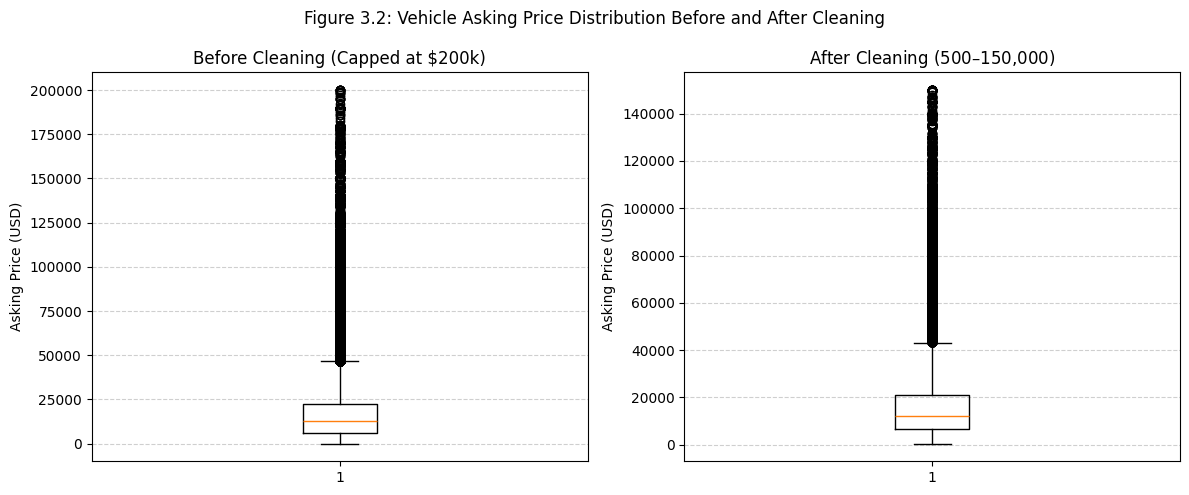

Saved: vehicles_cleaned.csv


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_raw = pd.read_csv("vehicles.csv")
df = df_raw.copy()

audit_log = []
def log_step(step_name, current_df):
    audit_log.append({
        'Step': step_name,
        'Rows Remaining': len(current_df),
        'Rows Removed': len(df_raw) - len(current_df),
        'Retained (%)': round(len(current_df) / len(df_raw) * 100, 2)
    })

log_step("0. Raw Dataset Loaded", df)

# 1. Drop 100% empty, >95% empty, URLs, IDs, and redundant address columns
cols_to_drop = [
    'id', 'url', 'region_url', 'image_url', 'image_urls', 'VIN',
    'description', 'title', 'size', 'county', 'other_attributes',
    'monthly_payment', 'updated_date', 'address_street',
    'address_postal_code', 'address_state', 'address_city', 'address_country'
]
df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])
log_step("1. Dropped Empty/URL/ID/Redundant Columns", df)

# 2. Convert 'price' from string/object to numeric
df['price'] = pd.to_numeric(df['price'].astype(str).str.replace(r'[$,]', '', regex=True), errors='coerce')

# 3. Remove duplicate vehicle listings
dup_subset = ['year', 'manufacturer', 'model', 'odometer', 'price', 'state', 'transmission', 'fuel']
df = df.drop_duplicates(subset=dup_subset, keep='first')
log_step("2. Removed Duplicate Vehicle Listings", df)

# 4. Filter invalid/outlier prices ($500 to $150,000)
df = df.dropna(subset=['price'])
df = df[(df['price'] >= 500) & (df['price'] <= 150000)]
log_step("3. Filtered Invalid & Outlier Prices ($500–$150k)", df)

# 5. Filter invalid years (keep 1980 to 2026)
df = df.dropna(subset=['year'])
df = df[(df['year'] >= 1980) & (df['year'] <= 2026)]
df['year'] = df['year'].astype(int)
log_step("4. Filtered Invalid Years (1980–2026)", df)

# 6. Filter invalid odometer (1 to 500,000 miles; keep NaN for train-split imputation)
df = df[(df['odometer'].isna()) | ((df['odometer'] > 0) & (df['odometer'] <= 500000))]
log_step("5. Filtered Invalid Odometer (1–500k miles)", df)

# 7. Standardise text categories & parse cylinders
cat_cols = ['region', 'manufacturer', 'model', 'condition', 'fuel',
            'title_status', 'transmission', 'drive', 'type', 'paint_color', 'state', 'seller_type']
for col in cat_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.lower().str.strip()
        df[col] = df[col].replace({'nan': np.nan, 'none': np.nan, '': np.nan})
        df[col] = df[col].fillna('unknown')

df['cylinders_num'] = df['cylinders'].astype(str).str.extract(r'(\d+)').astype(float)
df = df.drop(columns=['cylinders'])
df['posting_date'] = pd.to_datetime(df['posting_date'], errors='coerce', utc=True)

log_step("6. Standardised Text & Filled Categorical NaNs", df)

# Print outputs for Report
print("=== TABLE 3.7: DATA CLEANING AUDIT SUMMARY ===")
audit_df = pd.DataFrame(audit_log)
display(audit_df)

print(f"\nFinal Cleaned Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
print("\nRemaining Missing Values (Numeric only - for Pipeline Imputation in Stage 5):")
print(df.isna().sum()[df.isna().sum() > 0])

# Save Before/After Boxplot (converting raw price to numeric first)
raw_price_num = pd.to_numeric(df_raw['price'].astype(str).str.replace(r'[$,]', '', regex=True), errors='coerce').dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].boxplot(raw_price_num[raw_price_num <= 200000], vert=True)
axes[0].set_title('Before Cleaning (Capped at $200k)')
axes[0].set_ylabel('Asking Price (USD)')
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

axes[1].boxplot(df['price'], vert=True)
axes[1].set_title('After Cleaning ($500 – $150,000)')
axes[1].set_ylabel('Asking Price (USD)')
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.suptitle('Figure 3.2: Vehicle Asking Price Distribution Before and After Cleaning')
plt.tight_layout()
plt.savefig('outputs/figures/fig_3_2_price_before_after.png', dpi=300)
plt.show()

df.to_csv("vehicles_cleaned.csv", index=False)
print("Saved: vehicles_cleaned.csv")

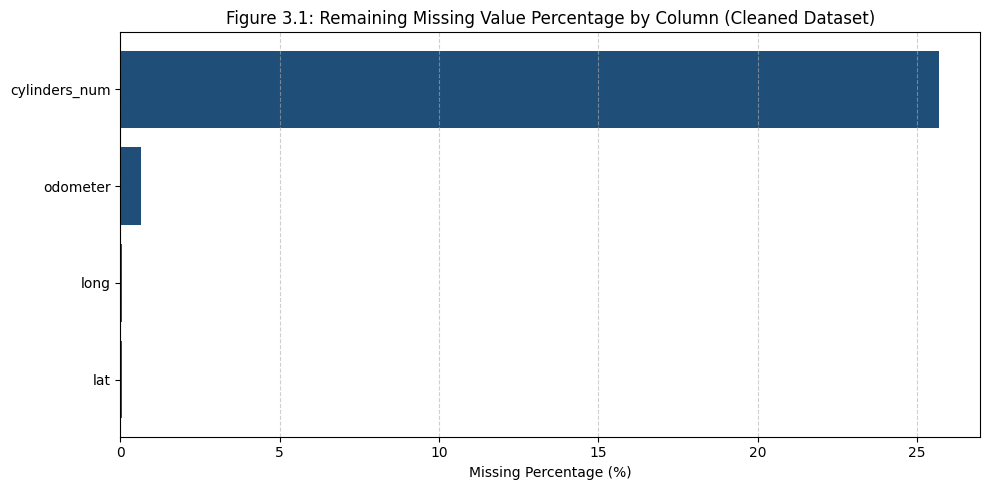

Saved: fig_3_1_missing_values_cleaned.png


In [23]:
# ==========================================
# CELL 5: Figure 3.1 - Missing Values Bar Chart (Post-Cleaning)
# ==========================================
# Cleaned dataset (df) se fresh missing percentages calculate karein
missing_after = pd.DataFrame({
    'Missing %': (df.isnull().sum() / len(df)) * 100
})
missing_plot = missing_after[missing_after['Missing %'] > 0].sort_values(by='Missing %', ascending=True)

plt.figure(figsize=(10, 5))
plt.barh(missing_plot.index, missing_plot['Missing %'], color='#1F4E79')
plt.xlabel('Missing Percentage (%)')
plt.title('Figure 3.1: Remaining Missing Value Percentage by Column (Cleaned Dataset)')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('outputs/figures/fig_3_1_missing_values_cleaned.png', dpi=300)
plt.show()
print("Saved: fig_3_1_missing_values_cleaned.png")